# Notebook #07 — Fail-Closed Deployment (`predict_risk`) & 4-Tier Drift Monitoring

### Nội dung cốt lõi
1. **Model Loading & Integrity Checks:** Nạp Production bundle qua `load_production_artifacts()` (fail-closed nếu `approved != True`, checksum SHA-256 sai lệch, hoặc thiếu causal store).
2. **`predict_risk()` Execution:** Dự đoán 3 lớp ICAO + `predicted_delay_minutes` + `factors` trước `T-3h`, đồng thời chặn payload có `prediction_time > scheduled_dt` hoặc chứa cột rò rỉ.
3. **Training-Serving Parity Check:** Đối chứng vector biến đổi từ `FeatureBuilder.build_single()` khớp tuyệt đối `<= 1e-6` với ma trận `test.csv` từ Notebook #03/#04.
4. **4-Tier Drift Monitoring (Data Quality, PSI + KS-Test, Chi-Square, Concept Drift):** Trực quan hóa mức độ trôi đặc trưng.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flight_delay.common.constants import FILE_GOLD, PROCESSED_DIR, REPORTS_DIR
from flight_delay.common.exceptions import InvalidPredictionTimeError
from flight_delay.data_mining.feature_engineering.builder import FeatureBuilder
from flight_delay.inference.model_loader import load_production_artifacts
from flight_delay.inference.predict import predict_risk

bundle = load_production_artifacts()
gold_te = pd.read_csv(FILE_GOLD, low_memory=False)
gold_te = gold_te[gold_te["split_role"] == "test"].reset_index(drop=True)
mat_te = pd.read_csv(PROCESSED_DIR / "test.csv")

# Parity verification on holdout sample
fb = FeatureBuilder(horizon_hours=3, history_store=bundle.history_store)
row = gold_te.iloc[0]
vec_single = bundle.preprocessor.transform(
    fb.build_single(
        airline_code=str(row["airline_code"]), airport=str(row["airport"]),
        direction=str(row["direction"]), route_type=str(row["route_type"]),
        scheduled_time=str(row["scheduled_time"])[:5], flight_date=str(row["flight_date"]),
        precipitation=float(row["precipitation"]), wind_gusts_10m=float(row["wind_gusts_10m"]),
        visibility=float(row["visibility"]), weather_code=int(row["weather_code"]),
        airport_load=int(round(float(row["airport_load"]))),
        origin=str(row["origin"]), destination=str(row["destination"]),
        prediction_time=str(row["prediction_time"]),
    )
)[0]
vec_batch = mat_te.iloc[0][bundle.preprocessor.feature_names].to_numpy(dtype=float)
max_diff = float(np.max(np.abs(vec_single - vec_batch)))
assert max_diff < 1e-6
print(f"Training-Serving Parity Verified: max absolute delta = {max_diff:.2e}")

# Example pre-flight risk prediction & fail-closed guardrail demo
res = predict_risk({
    "airline_code": "VJ", "airport": "SGN", "scheduled_time": "19:30", "flight_date": "2026-11-06",
    "precipitation": 12.0, "wind_gusts_10m": 40.0, "visibility": 3000.0, "weather_code": 95, "airport_load": 34
}, prediction_time="2026-11-06 16:30:00", bundle=bundle)
print("\nSample predict_risk() Response:")
print(json.dumps(res, indent=2, ensure_ascii=False))

try:
    predict_risk({"airline_code": "VN", "airport": "SGN", "scheduled_time": "10:00", "flight_date": "2026-11-06"}, prediction_time="2026-11-06 11:00:00")
except InvalidPredictionTimeError as e:
    print("\nFail-Closed Guardrail Confirmed:", e)

Training-Serving Parity Verified: max absolute delta = 9.02e-17

Sample predict_risk() Response:
{
  "predicted_class": "delayed",
  "probabilities": {
    "on_time": 0.1531,
    "delayed": 0.8433,
    "cancelled": 0.0036,
    "disrupted": 0.8469
  },
  "probabilities_pct": {
    "on_time": 15.3,
    "delayed": 84.3,
    "cancelled": 0.4,
    "disrupted": 84.7
  },
  "risk_tier": "HIGH",
  "risk_level": "Cao",
  "risk_color": "danger",
  "recommendation": "Cảnh báo rủi ro gián đoạn cao: chuẩn bị phương án điều phối slot, cổng ra tàu bay và hành khách nối chuyến.",
  "predicted_delay_minutes": 22.6,
  "estimated_delay_minutes": 22.6,
  "model_version": "flight_delay_classifier_3class:v2.0.0",
  "regressor_version": "flight_delay_regressor_mae:v2.0.0",
  "dataset_version": "2026.11.02-h3-4716bcd4",
  "prediction_time": "2026-11-06 16:30:00",
  "horizon_hours": 3,
  "latency_ms": 53.46,
  "factors": [
    "Cảnh báo dông bão (WMO >= 95)",
    "Mưa lớn (12.0 mm/h)",
    "Gió giật mạnh (40.0

Monitoring Overall Status: CRITICAL | Retrain Recommended: True
Alerts: [
  {
    "tier": "data_drift",
    "severity": "CRITICAL",
    "message": "Max feature PSI=4.6229 exceeds critical threshold."
  },
  {
    "tier": "concept_drift",
    "severity": "WARNING",
    "message": "Disruption rate shifted by 8.67 pp."
  }
]

                       feature    psi    ks_p   status
                 airport_load 0.0613 0.00000   STABLE
           airport_congestion 0.0445 0.00000   STABLE
                precipitation 0.0182 0.00007   STABLE
               wind_gusts_10m 0.1869 0.00000  WARNING
                   visibility 0.0760 0.00000   STABLE
         weather_hazard_score 0.0967 0.00000   STABLE
historical_airline_delay_rate 4.6229 0.00000 CRITICAL
historical_airport_delay_rate 4.5591 0.00000 CRITICAL


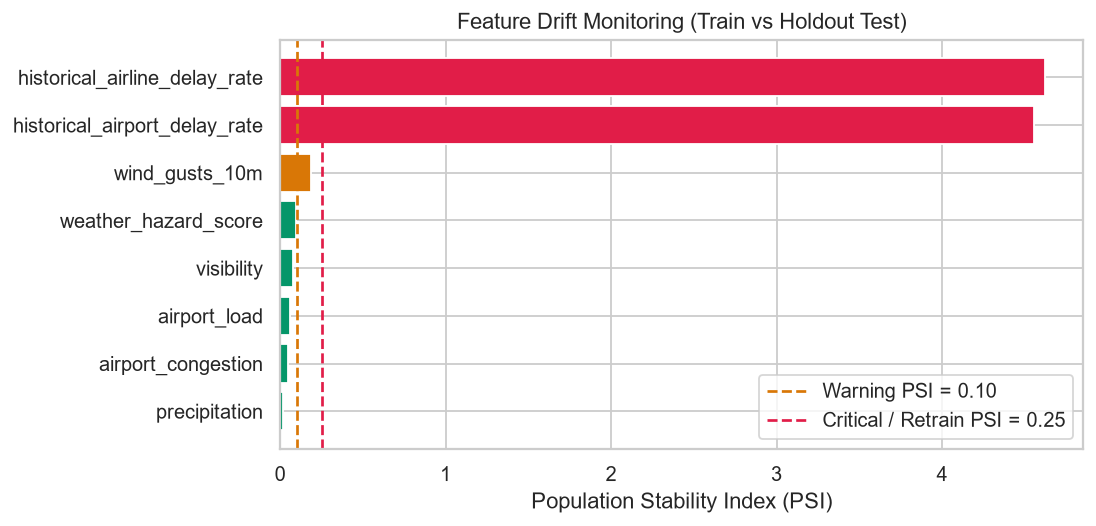

In [2]:
# 4-Tier Monitoring Summary & Feature Drift Plot
drift = json.loads((REPORTS_DIR / "monitoring" / "drift_report.json").read_text(encoding="utf-8"))
print(f"Monitoring Overall Status: {drift['overall_status']} | Retrain Recommended: {drift['retrain_recommended']}")
print("Alerts:", json.dumps(drift["alerts"], indent=2, ensure_ascii=False))
f_df = pd.DataFrame([{"feature": k, "psi": v["psi"], "ks_p": v["ks_p_value"], "status": v["status"]} for k, v in drift["data_drift"]["feature_drift"].items()])
print("\n", f_df.to_string(index=False))

f_sorted = f_df.sort_values("psi")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
cols = ["#e11d48" if p >= 0.25 else "#d97706" if p >= 0.10 else "#059669" for p in f_sorted["psi"]]
ax.barh(f_sorted["feature"], f_sorted["psi"], color=cols)
ax.axvline(0.10, color="#d97706", ls="--", label="Warning PSI = 0.10")
ax.axvline(0.25, color="#e11d48", ls="--", label="Critical / Retrain PSI = 0.25")
ax.set_xlabel("Population Stability Index (PSI)")
ax.set_title("Feature Drift Monitoring (Train vs Holdout Test)")
ax.legend()
fig.tight_layout()
plt.show()